# Cell fate decision

This notebook reproduces the analysis of the cell fate model of the [MaBoSS website](https://maboss.curie.fr).

The model is based on a published Boolean model ([Calzone et al., 2010](https://doi.org/10.1371/journal.pcbi.1000702)).
It describes how a cell chooses between three different fates, apoptosis, survival (NFκB activation) and
necroptosis (non-apoptotic cell death, NonACD), in response to the engagement of death receptors (here TNF).

Mutants are included in the model as external variables: `$gene_del` for a deletion and `$gene_oe` for an
over-expression. They are set to 0 for the wild type, and to 1 to simulate the mutant.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), and the files `CellFateModel.bnd` and
`CellFateModel.cfg`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


## The model

Only the three phenotype nodes, `Apoptosis`, `Survival` and `NonACD`, are output nodes: all the other nodes
are internal.

In [2]:
model = maboss.load("CellFateModel.bnd", "CellFateModel.cfg")
mutants = [name for name in model.param if name.endswith("_del") or name.endswith("_oe")]
print("Mutant parameters:", ", ".join(mutants))
print("Output nodes:", ", ".join(node for node in model.network if not model.network[node].is_internal))

Mutant parameters: $FADD_del, $RIP1_del, $NFkB_del, $NFkB_oe, $CASP8_del, $BAX_del, $BCL2_oe, $cIAP_del, $XIAP_del, $APAF_del, $cFLIP_del
Output nodes: NonACD, Apoptosis, Survival


We define a function to simulate the wild type, or a given mutant: all the mutant parameters are first set to 0.

In [3]:
def simulate(mutant=None):
    sim = model.copy()
    for name in mutants:
        sim.param[name] = 0
    if mutant is not None:
        sim.param[mutant] = 1
    return sim.run()

results = {
    "Wild type": simulate(),
    "CASP8 deletion": simulate("$CASP8_del"),
    "XIAP deletion": simulate("$XIAP_del"),
}

## Wild type

In the wild type, the probabilities of the three phenotypes evolve as follows: survival is transiently
activated, before most of the cells die by apoptosis.

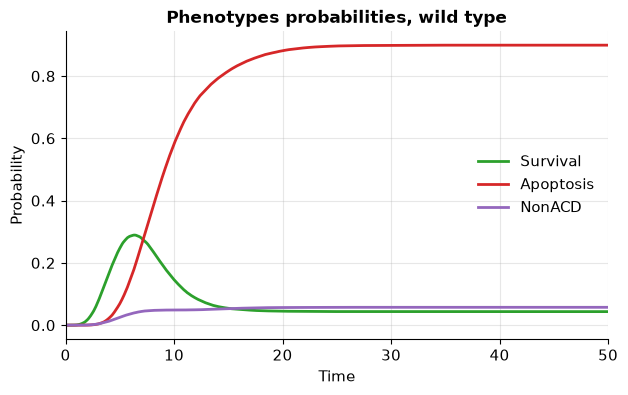

In [4]:
PHENOTYPES = ["Survival", "Apoptosis", "NonACD"]
PHENOTYPE_COLORS = {"Survival": COLORS[2], "Apoptosis": COLORS[3], "NonACD": COLORS[4], "<nil>": "#7F7F7F"}

nodes = results["Wild type"].get_nodes_probtraj()
fig, ax = plt.subplots()
for phenotype in PHENOTYPES:
    ax.plot(nodes.index, nodes[phenotype], label=phenotype, color=PHENOTYPE_COLORS[phenotype])
ax.set_xlim(0, 50)
ax.set_xlabel("Time")
ax.set_ylabel("Probability")
ax.set_title("Phenotypes probabilities, wild type")
ax.legend()
save(fig, "cellfate_wt_trajectories")

The three phenotypes are reachable, as in the published model. The probabilities differ slightly from the
published ones: they are not absolute values, as they depend on the computation and on the details of the
model (in the published model, the trajectories were computed over the transition graph).

## Mutants

We compare the final distribution of the phenotypes for the wild type and two mutants. The deletion of CASP8
leads to the disappearance of apoptosis, in accordance with published experiments.

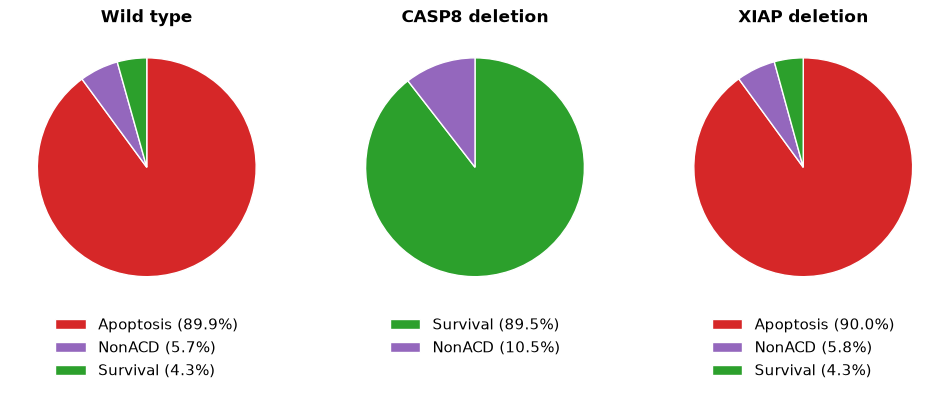

In [5]:
def phenotype_pie(result, ax, title):
    final = result.get_last_states_probtraj().iloc[0]
    final = final[final >= 0.001].sort_values(ascending=False)
    labels = [state_label(s) if s != "<nil>" else "no phenotype" for s in final.index]
    colors = [PHENOTYPE_COLORS.get(s, "#D9D9D9") for s in final.index]
    wedges, _ = ax.pie(final.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{l} ({p:.1%})" for l, p in zip(labels, final.values)],
              loc="upper center", bbox_to_anchor=(0.5, 0))
    ax.set_title(title)
    ax.set_aspect("equal")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, (name, result) in zip(axes, results.items()):
    phenotype_pie(result, ax, name)
save(fig, "cellfate_mutants")